In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections.abc import Callable
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec
from scipy.linalg import eig, eigvals
import scipy.sparse.linalg as sc
from scipy.integrate import ode, solve_ivp
from scipy.interpolate import PchipInterpolator

In [2]:




def dip_norm(phir,phid):
    return 1-3*(np.cos(phir-phid))**2

def dip_first_der_norm(phir,phid):
    return -3*np.cos(phir)+15*np.cos(phir)*np.cos(phir-phid)**2-6*np.cos(phid)*np.cos(phir-phid)

def dip_second_der_norm(phir,phid):
    return -3+15*np.cos(phir-phid)**2-6*np.cos(phid)**2+\
        60*np.cos(phir)*np.cos(phid)*np.cos(phir-phid)+15*np.cos(phir)**2*(1-7*np.cos(phir-phid)**2)

def nom_der1(DelR,d):
    r = np.linalg.norm(DelR)
    rx = DelR[0]/r
    ry = DelR[1]/r
    
    f = -3*rx + 15*rx*(rx*d[0]+ry*d[1])**2-6*d[0]*(rx*d[0]+ry*d[1])
    return f/r**4

def nom_der1_vec(DelR,d):
    r = np.linalg.norm(DelR,axis=1)
    rx = DelR[:,0]/r
    ry = DelR[:,1]/r
    
    f = -3*rx + 15*rx*(rx*d[0]+ry*d[1])**2-6*d[0]*(rx*d[0]+ry*d[1])
    # return np.where(r>=a,0,f/r**4)
    return f/r**4

def dip_derivative_full_vec(Delta_R_vec: np.ndarray, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec,axis=1)
    i = j = 0
    rx = Delta_R_vec[:,0]
    ry = Delta_R_vec[:,1]
    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0
    dot = (rx*d[0]+ry*d[1])
    if i == j:
        potential += 3/ Del_R**5-15*dot**2/Del_R**7
    potential += 6/ Del_R**5*d[0]**2
    potential -= 60*(d[0]*rx)*dot/Del_R**7
    potential -= 15*rx**2*(1/Del_R**7-7*dot**2/Del_R**9)
    return potential
    return np.where(Del_R>=a,0,potential)

def dip_derivative_ffull_vec(Delta_R_vec: np.ndarray, i:int, j:int, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec,axis=1)
   
    rx = Delta_R_vec[:,0]
    ry = Delta_R_vec[:,1]
    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0
    dot = (rx*d[0]+ry*d[1])
    if i == j:
        potential += 3/ Del_R**5-15*dot**2/Del_R**7
    potential += 6/ Del_R**5*d[0]**2
    potential -= 60*(d[0]*rx)*dot/Del_R**7
    potential -= 15*rx**2*(1/Del_R**7-7*dot**2/Del_R**9)
    return potential

def dip_derivative_full(Delta_R_vec: np.ndarray, i: int, j: int, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec)

    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0

    if i == j:
        potential += 3/ Del_R**5-15*np.dot(d,Delta_R_vec)**2/Del_R**7
    potential += 6/ Del_R**5*d[i]*d[j]
    potential -= 30*(d[i]*Delta_R_vec[j]+d[j]*Delta_R_vec[i])*np.dot(d,Delta_R_vec)/Del_R**7
    potential -= 15*Delta_R_vec[i]*Delta_R_vec[j]*(1/Del_R**7-7*np.dot(d,Delta_R_vec)**2/Del_R**9)
    # return Del_R
    return potential

def dip_dip(r_vec,d):
    r = np.linalg.norm(r_vec)
    if r==0:
        return 0
    potential = 1/r**3 * (1- 3*(np.dot(d,r_vec)/r)**2)
    return potential

# def nom_der1(dx,phi):
#     rx = np.cos(phi)
#     ry = np.sin(phi)
#     dy = np.sqrt(1-dx**2)
#     f = -3*rx + 15*rx*(rx*dx+ry*dy)**2-6*dx*(rx*dx+ry*dy)
#     return f

def dip_zero_der(b,h):
    phi = np.arctan(h/b)
    bracket = (max(-1,0-phi/2*2.8),max(0,0.7-phi/2))
    # bracket = (0,1)
    if nom_der1(bracket[0],phi)*nom_der1(bracket[1],phi)<=0:
        root = root_scalar(nom_der1,args=phi,bracket=bracket)
        # root = root_scalar(func,args=phi,x0=0)
        return root.root
    return 0 


def dipole_trap_onsite(i: int, j:int) -> float:
    if i==j:
        return 1
    else:
        return 0

def max_phi(r):
    return min(np.arccos((np.sqrt(1+2*r**2)-1)/2/r),np.arccos((r-1)/r))

def d_1(a,e):
    d = 0.9
    r1 = np.sqrt(a**2+e**2)
    r2 = np.sqrt(1+e**2)
    A = 12*(1/r1**5+1/r2**5)-7*15*(a**2*e**2/r1**9+e**2/r2**9)
    B = 15*(a*e/r1**7-e/r2**7)
    res =  B**2*(1-d**2)/(A**2*d**2+B**2*(1-d**2))
    return np.array([np.sqrt(res),np.where(A*B>=0,1,-1)*np.sqrt(1-res)])

def interaction_rotated(DelR,i,j,interaction_radius,d1):
    r = np.sqrt(DelR[0]**2+DelR[1]**2)
    d2 =0.9
    if r ==0:
        return 0
    if r>interaction_radius+0.01:
        return 0

    if i==j:
        B = -3/r**5+15*DelR[i]**2/r**7
        A = 45*DelR[0]*DelR[1]/r**7-7*15*DelR[0]*DelR[1]*DelR[i]**2/r**9
        return A*d1[0]*d2 - B*d1[1]*np.sqrt(1-d2**2)
    else:
        A = 12/r**5-7*15*DelR[0]**2*DelR[1]**2/r**9
        B = 15 *DelR[0]*DelR[1]/r**7
        return d1[0]*d2*A-B*d1[1]*np.sqrt(1-d2**2)
    

def phi_1(a,e):
    r1 = np.sqrt(a**2+e**2)
    r2 = np.sqrt(1+e**2)
    B = (12*(1/r1**5+1/r2**5)-7*15*(a**2*e**2/r1**9+e**2/r2**9))*(-1)
    A = 45*(a*e/r1**7-e/r2**7)-7*15*(a**3*e/r1**9-e/r2**9)
    res =  np.arctan(A/B)+np.where(B>=0,1,-1)*np.pi*(1-np.where(B>=0,1,-1))/2
    return res

def d_plane(a,e):
    d = 0.7
    phi = phi_1(a,e)
    return d*np.array([np.cos(phi),np.sin(phi)])

def phi_2(r,phi):
    B  = (-1)*(24/r**5-7*15*np.cos(phi)**2*np.sin(phi)**2/r**5)
    A = 45*np.cos(phi)*np.sin(phi)/r**5-7*15*np.cos(phi)**3*np.sin(phi)/r**5
    res =  np.arctan(A/B)+np.where(B>=0,1,-1)*np.pi*(1-np.where(B>=0,1,-1))/2
    return res

def d_plane_2(r,phi):
    d = 0.7
    phi_d = phi_2(r,phi)
    return d*np.array([np.cos(phi_d),np.sin(phi_d)])

def interaction_dipplain(DelR,i,j,interaction_radius,d):
    r = np.sqrt(DelR[0]**2+DelR[1]**2)
    if r ==0:
        return 0
    if r>interaction_radius+0.01:
        return 0
    
    
    if i==j:
        A = -3/r**5+15*(DelR[0]**2+DelR[i]*DelR[0]*2+ DelR[i]**2)/r**7-7*15*DelR[0]**2*DelR[i]**2/r**9
        B = 15*DelR[0]*DelR[1]/r**7-7*15*DelR[0]*DelR[1]*DelR[i]**2/r**9
        if i==0:
            A += 15*2*DelR[0]**2/r**7-6/r**5
            B += 30*DelR[0]*DelR[1]/r**7
        return A*d[0] + B*d[1]
    else:
        B = 12/r**5-7*15*DelR[0]**2*DelR[1]**2/r**9
        A = 45*DelR[0]*DelR[1]/r**7-7*15*DelR[0]**3*DelR[1]/r**9
        return A*d[0] + B*d[1]  
    
def max_b(h,a):
    return np.sqrt((a-0.011)**2-h**2)

def Vxy_decomp(x,y):
    r = np.sqrt(x**2+y**2)
    A = 24/r**5-7*30*x**2*y**2/r**9
    C = 45*x*y/r**7
    B = -7*15*x**3*y/r**9
    D = -7*15*x*y**3/r**9
    return np.array([A, B, C, D])

def Vxy(DelR,d):
    A, B, C, D = Vxy_decomp(DelR[0],DelR[1])
    return A*d[0]*d[1]+C+B*d[0]**2+D*d[1]**2

def Vaa(DelR,i,d):
    r = np.sqrt(DelR[0]**2+DelR[1]**2)
    A = -3/r**5+15*(DelR[0]**2*d[0]**2+DelR[1]**2*d[1]**2+2*DelR[0]*DelR[1]*d[0]*d[1])/r**7
    B = -6*d[i]**2/r**5+30*(2*d[i]*DelR[i]*(DelR[0]*d[0]+DelR[1]*d[1]))/r**7
    C = 15*(DelR[i]**2/r**7-7*DelR[i]**2*(DelR[0]**2*d[0]**2+DelR[1]**2*d[1]**2+2*DelR[0]*DelR[1]*d[0]*d[1])/r**9)
    return A+B+C

def interaction_aligned_dip(DelR,i,j,interaction_radius,beta,d):
    r = np.linalg.norm(DelR)
    
    if r ==0:
        return 0
    if r>interaction_radius+0.01:
        return 0
    if i==j:
        return Vaa(DelR,i,d)*beta
    else:
        return Vxy(DelR,d)*beta


def d_aligned(b,h,a):
    A, B, C, D = Vxy_decomp(b,h)+Vxy_decomp(b-a,h)
    a = (D-B)**2+A**2
    bi = -(A**2+2*(C+D)*(D-B))
    c = (C+D)**2
    sq = np.sqrt(bi**2-4*a*c)
    ot = -bi
    dx = np.sqrt((ot+sq)/2/a)
    sign = np.where((-(C+D)+(D-B)*dx**2)*A>=0,1,-1)
    return np.array([dx,np.sqrt(1-dx**2)*sign])



In [3]:
class TickProperties():
    
    major_xtick_step = 5,
    minor_xtick_step = 1
    major_ytick_step = 5
    minor_ytick_step = 1
    STRIP_OF_ZEROS_X = False
    STRIP_OF_ZEROS_Y = False

    def __init__(self,\
    xtick_step_major = 5,\
    xtick_step_minor = 1,\
    ytick_step_major = 5,\
    ytick_step_minor = 1,\
    SZX = False,\
    SZY = False):
        self.major_xtick_step = xtick_step_major
        self.minor_xtick_step = xtick_step_minor
        self.major_ytick_step = ytick_step_major
        self.minor_ytick_step = ytick_step_minor
        self.STRIP_OF_ZEROS_X = SZX
        self.STRIP_OF_ZEROS_Y = SZY

class Format():
    numb_xticks = None
    numb_yticks = None
    custom_func_x = None
    custom_func_y = None
    x_scale = None
    y_scale = None
    x_precion = "{:.2f}"
    y_precion = "{:.2f}"
    def __init__(self,numb_xticks=None,numb_yticks=None,custom_funx=None,custom_funy=None,xscale=None,yscale=None,xprec="{:.2f}",yprec="{:.2f}"):
        self.numb_xticks =numb_xticks
        self.numb_yticks = numb_yticks
        self.custom_func_x = custom_funx
        self.custom_func_y = custom_funy
        self.x_precion=xprec
        self.y_precion = yprec
        self.x_scale = xscale
        self.y_scale = yscale
    def formatx0(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))
            # print(x,pos,self.numb_xticks)
            index = int((pos-1)*self.x_scale.shape[0]//self.numb_xticks)
            # print(index)
            # print(self.x_precion.format(self.x_scale[index]))
            return self.x_precion.format(self.x_scale[index])
        except:
            # print(self.x_precion.format(self.x_scale[-1]))
            return self.x_precion.format(self.x_scale[-1])
    def formatx1(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))
            print(pos)
            index = int((pos)*self.x_scale.shape[0]//self.numb_xticks)
            # print(index)
            # print()
            return self.x_precion.format(self.x_scale[index])
        except:
            return self.x_precion.format(self.x_scale[-1])
    
    def formaty1(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))

            index = int((pos-1)*self.y_scale.shape[0]//self.numb_yticks)
            # print(index)
            # print()
            return self.y_precion.format(self.y_scale[index])
        except:
            return self.y_precion.format(self.y_scale[-1])
        
    def formaty(self,x,pos):
        try:
            return self.y_precion.format(self.y_scale[int(x)])
        except:
            return ""

class Setup_Fig():
    DEFAULT_HEAT_EXTEND = (-0.5,39.5,29.5,-0.5)
    xlim = None
    ylim = None
    tickprop = TickProperties()
    formatter = Format()
    cm = 1/2.54 
    fig_width = 12*cm
    fig_height = 4.8/6.4*12*cm
    name_of_plot = None
    xax_share = None
    yax_share = None
    def __init__(self,name_of_plot = "sign_of_ev1.pdf",xlim=None,ylim=None,tickp=TickProperties(),formater=Format(),xax_share = False, yax_share = False,fig_width = 12*cm,fig_height = 4.8/6.4*12*cm):
        self.xlim=xlim
        self.ylim = ylim   
        self.tickprop =tickp       
        self.formatter = formater
        self.name_of_plot = name_of_plot
        self.xax_share = xax_share 
        self.yax_share = yax_share 
        self.fig_height = fig_height
        self.fig_width = fig_width


    
    plt.rcParams["lines.markersize"]=0.7
    plt.rcParams["axes.unicode_minus"]=True
    plt.rcParams["font.size"]=10
    plt.rcParams["text.usetex"]=True
    plt.rcParams["font.serif"]="Computer Modern Serif"
    plt.rcParams["text.latex.preamble"] = r"\usepackage{physics}\usepackage{amsmath}"

# ax.scatter(A,root,color='0')
    



    def return_fig(self,shape=(1,1),dots_per_inch=400,heightratio=None):
        if heightratio:
            fig, ax = plt.subplots(*shape,figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch,sharex=self.xax_share,sharey=self.yax_share,height_ratios=heightratio)
        else:
            fig, ax = plt.subplots(*shape,figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch,sharex=self.xax_share,sharey=self.yax_share)
        # trash, xw, yw, trash=self.DEFAULT_HEAT_EXTEND# im.get_extent()
        # self.formatter.numb_xticks = xw//self.tickprop.major_xtick_step
        # self.formatter.numb_yticks = yw//self.tickprop.major_ytick_step
        return fig, ax
    
    def return_gridspec(self,shape=(1,1),dots_per_inch=400):
        fig = plt.figure(figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch)
        gs = gridspec.GridSpec(*shape, figure=fig)
        return fig, gs
        if shape[0]==1 or shape[1]==1:
            num = max(shape)
            axes = np.empty((num),dtype=object)
            for i in range(shape[0]):
                for j in range(shape[1]):
                    axes[i+j] = fig.add_subplot(gs[i,j])
        else:
            axes = np.empty(shape,dtype=object)
            # axes = []
            for i in range(shape[0]):
                for j in range(shape[1]):
                    axes[i,j] =  fig.add_subplot(gs[i,j])
                    # axes.append(fig.add_subplot(gs[i,j]))
                # axes[-1].set_aspect('auto')
        return fig, axes

        
    def format_ax(self,current_ax,shape,tickprop=None,j=0,bottom=True,set_ticks=True):
        # print(f"format_ax called with j={j}, shape={shape}")
        trash, xw, yw, trash=self.DEFAULT_HEAT_EXTEND# im.get_extent()
        self.formatter.numb_xticks = (xw+0.5)//self.tickprop.major_xtick_step
        self.formatter.numb_yticks = (yw+0.5)//self.tickprop.major_ytick_step
        pos= 'outer_left'
        current_ax.set_aspect('auto')
        if shape[1]>1:
                if j==0:
                    pos= 'outer_left'
                elif j<shape[1]-1 or j==-1:
                    pos = 'middle'
                elif j==shape[1]-1:
                    pos = 'outer_right'
                


        # axlimits have to be adapted
        # try:
        #     current_ax.set_xlim(*self.xlim)
        # except:
        #     pass
        # try:
        #     current_ax.set_ylim(*self.ylim)
        # except:
        #     pass    
    
        if set_ticks:
            if tickprop.STRIP_OF_ZEROS_X:
                current_ax.xaxis.set_major_formatter(ticker.FuncFormatter(self.formatter.formatx0))
            current_ax.yaxis.set_major_locator(ticker.MultipleLocator(tickprop.major_ytick_step))
            current_ax.yaxis.set_minor_locator(ticker.MultipleLocator(tickprop.minor_ytick_step))
            current_ax.xaxis.set_major_locator(ticker.MultipleLocator(tickprop.major_xtick_step))
            current_ax.xaxis.set_minor_locator(ticker.MultipleLocator(tickprop.minor_xtick_step))

            if tickprop.STRIP_OF_ZEROS_Y:
                current_ax.yaxis.set_major_formatter(ticker.FuncFormatter(self.formatter.formaty1))  

        if self.xax_share:
            
            if not bottom:
                current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=False)
            else:
                current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=True)
        else:
            current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=True)

        if self.yax_share:    
            if pos=='outer_left':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=True)
            elif pos=='middle':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=False)
            elif pos=='outer_right':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelright=True,labelleft=False)
            #     current_ax.yaxis.set_label_position("right")
                # current_ax.set_xlabel(r'$\Gamma \tilde{A}$')
                # current_ax.set_ylabel(r'$\tilde{y}$',rotation=0)
        
        else:    
            current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=True)   


        current_ax.tick_params(axis='both',which='major',length=4.5)
        plt.setp(current_ax.yaxis.get_majorticklabels(),va='center')
        
        return current_ax

In [4]:
from multiprocessing import Pool
from functools import partial

# def real_index(index,index_range,index_number,base):
#         real = []
        
#         for i in range(index_number-1):
#             if type(index_range[i]) is list:
#                 if not isinstance(index_range[i][0], int):
#                     raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
#                 projected_range = index_range[i][1] - index_range[i][0]
#             else:
#                 projected_range = index_range[i]
#             real.append(index//projected_range+base[i])
#             index = index-real[i]*projected_range
#         real.append(index+base[-1])
#         return real

def real_index(index,mat_range,index_number,base):
        real = np.zeros(index_number,dtype=np.int16)
        real[-1] = index%mat_range[-1]+base[-1]
        index = index//mat_range[-1]

        for i in range(1,index_number):
            real[-1-i] = index%mat_range[-1-i]+base[-1-i]
            index = index//mat_range[-1-i]
        # print(index)
        return real

def matrix_index(index,index_range,index_number):
        real = []
        
        for i in range(index_number-1):
            if type(index_range[i]) is list:
                if not isinstance(index_range[i][0], int):
                    raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
                projected_range = index_range[i][1] - index_range[i][0]
            else:
                projected_range = index_range[i]
            real.append(index//projected_range)
            index = index-real[i]*projected_range
        real.append(index)
        return real

def wrapper(function,mat_range,index_number,base,args,x):
        # print(args)
        # print(real_index(x,mat_range,index_number,base))
        return function(*real_index(x,mat_range,index_number,base),*args)

def total_range(index_range):
    """Calculate the total range based on the index range."""
    ranges = []
    bases = []
    tot_range = 1
    for i in index_range:
        if type(i) is list:
            if not isinstance(i[0], int):
                raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
            else:
                 tot_range *= i[1]-i[0]
                 ranges.append(i[1]-i[0])
                 bases.append(i[0])
        else:
            tot_range *= i
            ranges.append(i)
            bases.append(0)
    return tot_range, ranges, bases


def parallel_for(index_range,function,*args,chunk=1,core_number=4,sort_in_array=False):
    index_number = len(index_range)
    tot_range = 1
    tot_range, virtual_range, base = total_range(index_range)
    # print("index protperties: ",tot_range, virtual_range, base)
    
    return parallelizer(tot_range,function,index_range,index_number,virtual_range,base,chunk,core_number,sort_in_array,*args)

    

def parallelizer(i_range,function,index_range,index_number,mat_range,base,chunk,core_number,sort_in_array,*args):
    po = Pool(core_number)
    if not args:
         args=[0]
    # print(type(function))
    # print(mat_range)
    result = po.imap(partial(wrapper,function,mat_range,index_number,base,args),np.arange(i_range),chunksize=chunk)
    first_val = next(result)
    try:
         shape = first_val.shape
         out = np.zeros([*mat_range,*shape],dtype=type(first_val[0]))
    except:
         try:
            shape = [len(first_val)]
            if np.all(type(x)==type(first_val[0]) for x in first_val):
                out = np.zeros([*mat_range,*shape],dtype=type(first_val[0]))
            else:
                out = np.zeros([*mat_range,*shape],dtype=object)
         except:
              
              out = np.zeros([*mat_range],dtype=object)
    if sort_in_array:
        pass
    
    # out = np.zeros([*mat_range,*shape],dtype=object)
    # print('first value: ',first_val)
    out[*real_index(0,mat_range,index_number,np.zeros(index_number,dtype=np.int16))] = first_val
    for index, res in enumerate(result,start=1):
        # print(index,real_index(index,mat_range,index_number,np.zeros(index_number,dtype=np.int16)),res)
        out[*real_index(index,mat_range,index_number,np.zeros(index_number,dtype=np.int16))] = res
        # print(real_index(index,index_range,index_number),res)
    return out


def function(i,base):
    # j = i%2
    # i= i//2
    j=0
    print("func_arg",i,j,base)
    return i+base,j+base

def additional_wrap(i,j,base):
     i+=10
     j+=10
     return function(i,j,base)
# index_range = [3,3]

# parallel_for([[0,2],[-1,2]],function,chunk=1)
parallel_for([[0,2]],function,chunk=1,core_number=4)
# real_index(np.arange(9),[3,3],2,[0,0])

func_argfunc_arg  10  00  00



array([[0, 0],
       [1, 0]], dtype=int16)

In [5]:
def sort_eigenvalues(eigenvalues: np.ndarray,eigenvectors: np.ndarray, edge_size: int = 1) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    # eigenvectors *= np.conjugate(eigenvectors[0, :])/np.absolute(eigenvectors[0,:])#np.array([np.absolute(eigenvectors[0,i]) for i in range(eigenvectors.shape[1])]) # Normalize the eigenvectors
    comb = np.column_stack((eigenvalues.T, eigenvectors.T))
    # return comb
    # sorted_comb = sorted(comb, key=lambda x: x[0])
    # sorted_comb = sorted(comb, key=lambda x: np.abs(x[0]-120))
    # sorted_comb = sorted(comb, key=lambda x: max(np.max(np.abs(x[1:edge_size+1])),np.max(np.abs(x[-edge_size:]))),reverse=True)
    sorted_comb = sorted(comb, key=lambda x: max(np.sum(np.abs(x[1:edge_size+1])**2),np.sum(np.abs(x[-edge_size:])**2)),reverse=True)
    return np.array(sorted_comb)
def sort_eigenvalues_energies(eigenvalues: np.ndarray,eigenvectors: np.ndarray, energy: float = 0) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    # eigenvectors *= np.conjugate(eigenvectors[0, :])/np.absolute(eigenvectors[0,:])#np.array([np.absolute(eigenvectors[0,i]) for i in range(eigenvectors.shape[1])]) # Normalize the eigenvectors
    comb = np.column_stack((eigenvalues.T, eigenvectors.T))
    # return comb
    sorted_comb = sorted(comb, key=lambda x: x[0])
    # sorted_comb = sorted(comb, key=lambda x: np.abs(x[0]-energy))
    # sorted_comb = sorted(comb, key=lambda x: max(np.max(np.abs(x[1:edge_size+1])),np.max(np.abs(x[-edge_size:]))),reverse=True)
    # sorted_comb = sorted(comb, key=lambda x: max(np.sum(np.abs(x[1:edge_size+1])**2),np.sum(np.abs(x[-edge_size:])**2)),reverse=True)
    return np.array(sorted_comb)

def sort_eigenvalues_gap(eigenvalues: np.ndarray,eigenvectors: np.ndarray,cut: int = 4) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    gap = np.abs(eigenvalues[3:]-eigenvalues[2:-1])+np.abs(eigenvalues[1:-2]-eigenvalues[:-3])
    comb = np.column_stack((gap.T,eigenvalues[3:].T, eigenvectors[:,3:].T))
    
    sorted_comb = sorted(comb, key=lambda x: x[0])
    return np.array(sorted(sorted_comb[:cut],key=lambda x: x[1],reverse=True))



In [6]:
import scipy.constants as c

a0 = 4*np.pi*c.epsilon_0*c.hbar**2/(c.m_e*c.e**2)
d = np.array([1000,10000])*c.e*a0
r0 = np.array([3])/10**6
V = d**2/(4*np.pi*c.epsilon_0*r0**3)#*np.sqrt(c.hbar/2/m/w)**2
display(V/c.hbar)
m = 85.5*c.u
w = 2*np.pi*10**3*np.array([100,2000])
r= np.array([3,12])/10**6
np.sqrt(c.hbar/m/2/w)**2/r**2, np.sqrt(c.hbar/2/m/w)

array([2.26894795e+08, 2.26894795e+10])

(array([6.56762844e-05, 2.05238389e-07]),
 array([2.43122718e-08, 5.43638924e-09]))

-552.9599999999999 8.72803724096948
-165.72815184059726 10.737125675840087
10.876714746815958 13.319836701474236
68.16980108366482 16.662961941154958
75.87741615288857 21.012684423682003
67.08203932499364 26.681717757670675
54.78826254364981 34.034052732255496
43.3992138918854 43.3992138918854
34.034052732255525 54.78826254364976
26.681717757670697 67.08203932499362
21.012684423681968 75.87741615288849
16.662961941154958 68.16980108366498
13.319836701474236 10.876714746815958
10.737125675840105 -165.7281518405965
8.72803724096948 -552.9599999999998


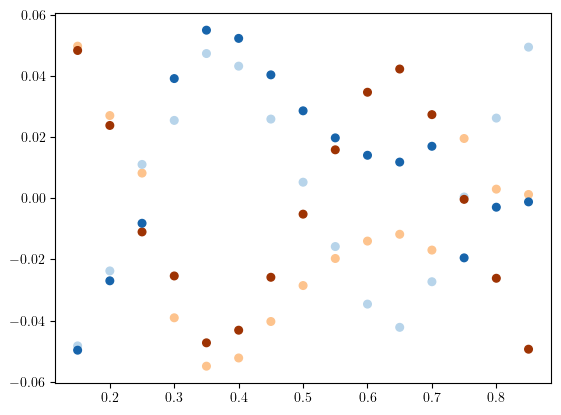

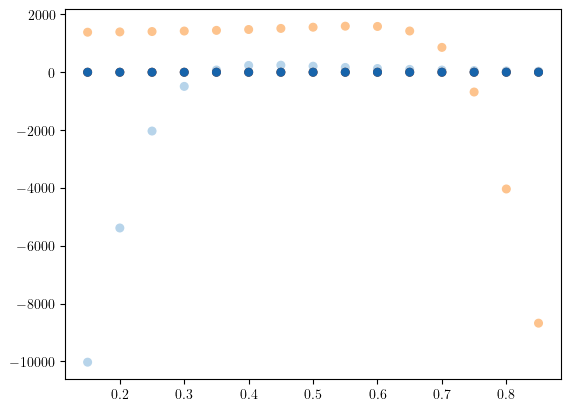

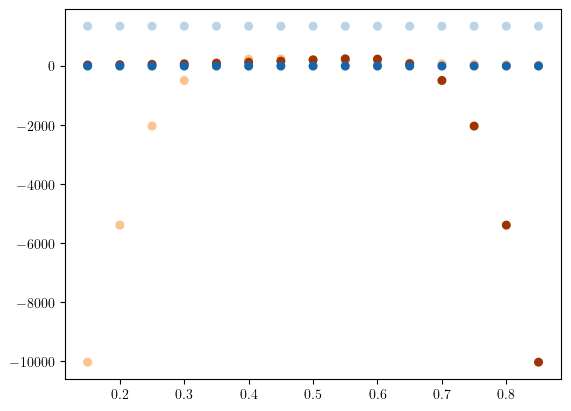

In [7]:
def grad(b,h,a,chain_length,interaction,d):
    latticeA = np.array([[0,0],[a,0]])
    latticeB = np.array([b,h])
    dist1 = latticeB-latticeA[0]
    dist2 = latticeA[1]-latticeB
    grad1 = interaction(dist1,d)
    grad2 = interaction(dist2,d)
    grad_vec = np.zeros(chain_length)
    print(grad1,grad2)
    grad_vec[0] = -grad1
    grad_vec[1:-1] = -grad2+grad1
    grad_vec[-1] = grad1-(grad1-grad2)*(chain_length%2)
    grad_vec[1:-1] *= (-1)**np.arange(chain_length-2)
    return grad_vec
    return grad1, grad2
    return dist1, dist2



def nearest_nb_Hamiltonian(b,h,a,chain_length,interaction,Delta,d):
    latticeA = np.zeros((2,chain_length//2+chain_length%2))
    latticeB = np.zeros((2,chain_length//2))
    for n in range(latticeA.shape[1]):
        latticeA[:,n] = n*np.array([1,0])*a
    for n in range(latticeB.shape[1]):
        latticeB[:,n] = n*np.array([1,0])*a + b * np.array([1,0])+h*np.array([0,1])
    dmat = np.zeros((chain_length,chain_length))
    ind = np.arange(chain_length,dtype=np.int16)
    inter_1 = interaction(latticeB[:,0]-latticeA[:,0],d)
    inter_2 = interaction(latticeB[:,0]-latticeA[:,1],d)
    dmat[ind[:-1:2],ind[1::2]]= inter_1
    dmat[ind[1::2],ind[:-1:2]]= inter_1
    dmat[ind[1:-1:2],ind[2::2]] = inter_2
    dmat[ind[2::2],ind[1:-1:2]] = inter_2
    dmat[0,0] = -inter_1
    dmat[-1,-1] = -inter_1-(inter_2-inter_1)*(chain_length%2)
    dmat[ind[1:-1],ind[1:-1]] = -inter_1-inter_2 

    # dmat[ind[2:-1:2],ind[2:-1:2]]= -Delta
    # print(inter_1,inter_2,b)
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]

def nearest_nb_Hamiltonian_test(alpha,b,h,a,chain_length,interaction,Delta,d):
    latticeA = np.zeros((2,chain_length//2+chain_length%2))
    latticeB = np.zeros((2,chain_length//2))
    for n in range(latticeA.shape[1]):
        latticeA[:,n] = n*np.array([1,0])*a
    for n in range(latticeB.shape[1]):
        latticeB[:,n] = n*np.array([1,0])*a + b * np.array([1,0])+h*np.array([0,1])
    dmat = np.zeros((chain_length,chain_length))
    ind = np.arange(chain_length,dtype=np.int16)
    inter_1 = interaction(latticeB[:,0]-latticeA[:,0],d)
    inter_2 = interaction(latticeB[:,0]-latticeA[:,1],d)
    dmat[ind[:-1:2],ind[1::2]]= inter_1
    dmat[ind[1::2],ind[:-1:2]]= inter_1
    dmat[ind[1:-1:2],ind[2::2]] = inter_2
    dmat[ind[2::2],ind[1:-1:2]] = inter_2
    dmat[0,0] = dmat[-1,-1] = alpha*np.max(np.abs(dmat))
    # dmat[0,0] = -inter_1
    # dmat[-1,-1] = -inter_1-(inter_2-inter_1)*(chain_length%2)
    # dmat[ind[1:-1],ind[1:-1]] = -inter_1-inter_2 


    # dmat[ind[2:-1:2],ind[2:-1:2]]= -Delta
    # print(inter_1,inter_2,b)
    return dmat #- np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


import matplotlib.cm as cm
orange = cm.Oranges
blue = cm.Blues
chain_length = 4
N = 15
# b = np.linspace(0.465,0.535,N)
b = np.linspace(0.15,0.85,N)
h = 0.2
a = 1
# d = np.array([np.sqrt(1/3),np.sqrt(2/3)])
d = np.array([1,0])
eigenvecs = np.zeros((N,chain_length))
dist1 = np.zeros(N)
dist2 = np.zeros(N)
fig, ax = plt.subplots(1,1)
fig2, ax2 = plt.subplots(1,1)
fig3, ax3 = plt.subplots(1,1)
colors = np.zeros((chain_length,4))
colors[::2] = orange(np.linspace(0.3,0.9,chain_length//2+chain_length%2))
colors[1::2] = blue(np.linspace(0.3,0.8,chain_length//2))
for i in range(N):
    dmat = nearest_nb_Hamiltonian(b[i],h,a,chain_length,lambda x, y: dip_derivative_full(x, 0, 0, y),0,d)
    dmat += np.diag(np.ones(chain_length))*(m*w**2*r**2/V)[-1]
    beta = grad(b[i],h,a,chain_length,nom_der1,d)
    # eig, vecs = np.linalg.eig(dmat)
    # eigenvecs[i,:] = sorted(eig)
    eigenvecs[i,:] = np.linalg.solve(dmat,beta)
    # ax.scatter(b[i]*np.ones(chain_length-2),beta[::3],color='0')
    # ax.scatter(b[i]*np.ones(chain_length-2),eigenvecs[i,2:],color=colors[:2],s=30)
    ax.scatter(b[i]*np.ones(chain_length),eigenvecs[i,:],color=colors,s=30)
    # dist1[i], dist2[i] = grad(b[i],h,a,chain_length,nom_der1,d)
    # ax.scatter(b[i]*np.ones(chain_length),beta,color='0')
    ax2.scatter(b[i]*np.ones(chain_length),dmat[:,0],color=colors,s=30)
    ax3.scatter(b[i]*np.ones(chain_length),dmat[:,1],color=colors,s=30)
    # ax.scatter(b[i]*np.ones(1),dist1,color='0')
    # ax.scatter(b[i]*np.ones(1),dist2,color='red')
# ax.scatter(b,dist1,color='0')
# ax.scatter(b,dist2[::-1],color='red')
# ax.set_ylim(-3,3)
plt.show()


In [8]:
# long range
def grad_long_range(b,h,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T 
    indA = np.arange(latticeA.shape[0],dtype=np.int16)
    indB = np.arange(latticeB.shape[0],dtype=np.int16)
    grad_vec = np.zeros(chain_length)
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),-interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),-interaction(latticeB[i:]-latticeA[i],d)))
        grad_vec[2*i] = np.sum(interAA[i])+np.sum(interAB[i])
    
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),-interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),-interaction(latticeA[i+1:]-latticeB[i],d)))
        grad_vec[2*i+1] = np.sum(interBB[i])+np.sum(interBA[i])
    # print(interAA)
    # print(interAB)
    # print(interBB)
    # print(interBA)
    if cut:
        return np.where(np.abs(grad_vec)<cut,0,grad_vec)
    return grad_vec

def hopping_Ham2(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T 
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,2::2] = interAA[i]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,2::2] = interBB[i]
        dmat[2*i+1,1::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    return dmat

def hopping_Ham(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat #- np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]

def hopping_Ham_alpha(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )* alpha
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) * alpha
        
    dmat[0,0] = dmat[-1,-1] = alpha*dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


def hopping_Ham_adapted(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    dmat[0,0] = dmat[-1,-1] = alpha+dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


def hopping_Ham_adapted_quadratic(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    # dmat[0,0] = dmat[-1,-1] = alpha+dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    # return dmat - np.diag((np.arange(chain_length)-chain_length//2+0.5)**2*(dmat[0,0]-dmat[chain_length//2,chain_length//2])/(chain_length//2-0.5)**2+dmat[chain_length//2,chain_length//2])
    return dmat - np.diag(np.exp((np.arange(chain_length)-chain_length//2+0.5)**2)*(dmat[0,0]-dmat[chain_length//2,chain_length//2])/np.exp((chain_length//2-0.5)**2)+dmat[chain_length//2,chain_length//2])


def hopping_Ham_adapted_random(rand_vec,b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    dmat[0,0] = dmat[-1,-1] = dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))0.3/alpha+
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    # return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]+np.diag(rand_vec/alpha)
    return dmat - np.diag(np.diag(dmat))+np.diag(rand_vec/alpha)

def hopping_Ham_block(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    lenA = latticeA.shape[0]
    lenB = latticeB.shape[0]
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[i,:i] = interAA[i][:i]
        dmat[i,i+1:lenA] = interAA[i][i:]
        dmat[i,lenA:] = interAB[i]
        dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[lenA+i,lenA:lenA+i] = interBB[i][:i]
        dmat[lenA+i,lenA+i+1:] = interBB[i][i:]
        dmat[lenA+i,:lenA] = interBA[i]
        dmat[lenA+i,lenA+i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat# + np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))




def hopping_Ham_xy(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_alpha(b,h,alpha,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_alpha(b,h,alpha,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,0,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_alpha(b,h,alpha,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_random(b,h,randvec,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_alpha(b,h,0,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,0,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_alpha(b,h,0,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat+ np.diag(randvec)

def hopping_Ham_xy_block(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_bblock(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    lenA = chain_length//2+chain_length%2
    lenB = chain_length//2
    dmat[:lenA,:lenA] = Hamxx[:lenA,:lenA]
    dmat[:lenA,lenA:2*lenA] = Hamxy[:lenA,:lenA]
    dmat[lenA:2*lenA,:lenA] = Hamxy[:lenA,:lenA]
    dmat[lenA:2*lenA,lenA:2*lenA] = Hamyy[:lenA,:lenA]
    dmat[:lenA,2*lenA:2*lenA+lenB] = Hamxx[:lenA,lenA:]
    dmat[:lenA,2*lenA+lenB:] = Hamxy[:lenA,lenA:]
    dmat[lenA:2*lenA,2*lenA:2*lenA+lenB] = Hamxy[:lenA,lenA:]
    dmat[lenA:2*lenA,2*lenA+lenB:] = Hamyy[:lenA,lenA:]

    dmat[2*lenA:2*lenA+lenB,:lenA] = Hamxx[lenA:,:lenA]
    dmat[2*lenA:2*lenA+lenB,lenA:2*lenA] = Hamxy[lenA:,:lenA]
    dmat[2*lenA:2*lenA+lenB,2*lenA:2*lenA+lenB] = Hamxx[lenA:,lenA:]
    dmat[2*lenA:2*lenA+lenB,2*lenA+lenB:] =  Hamxy[lenA:,lenA:]
    dmat[2*lenA+lenB:,:lenA] = Hamxy[lenA:,:lenA]
    dmat[2*lenA+lenB:,lenA:2*lenA] = Hamyy[lenA:,:lenA]
    dmat[2*lenA+lenB:,2*lenA:2*lenA+lenB] = Hamxy[lenA:,lenA:]
    dmat[2*lenA+lenB:,2*lenA+lenB:] = Hamyy[lenA:,lenA:]
    return dmat





def hopping_Ham_cut(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    def f(x):
        if x<0:
            return 0
        elif x>=chain_length:
            return chain_length
        else:
            return x
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[f(i-cut):i],d),interaction(latticeA[i+1:f(i+cut+1)]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[f(i-cut):i],d),interaction(latticeB[i:f(i+cut)]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[f(i-cut):i],d),interaction(latticeB[i+1:f(i+cut+1)]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[f(i+1-cut):i+1],d),interaction(latticeA[i+1:f(i+1+cut)]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    return dmat

def hopping_Ham_k(k,b,h,Delta,a,chain_length,interaction,d):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((2,2),dtype=np.complex128)
    
    distAA = np.zeros((latticeA.shape[0]-1,2))
    distAB = np.zeros((latticeB.shape[0],2))
    # print("lattice",latticeA[0]-latticeA[:0])
    i = chain_length//4
    distAA = np.concatenate((-latticeA[:i]+latticeA[i],latticeA[i+1:]-latticeA[i]))
    interAA = interaction(distAA,d)
    distAB = np.concatenate((-latticeB[:i]+latticeA[i],latticeB[i:]-latticeA[i]))
    interAB = interaction(distAB,d)

    distBB = np.zeros((latticeB.shape[0]-1,2))
    distBA = np.zeros((latticeA.shape[0],2))
    
    distBB = np.concatenate((-latticeB[:i]+latticeB[i],latticeB[i+1:]-latticeB[i]))
    interBB = interaction(distBB,d)
    distBA = np.concatenate((-latticeA[:i+1]+latticeB[i],latticeA[i+1:]-latticeB[i]))
    interBA = interaction(distBA,d)
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
    cell_list = [n for n in range(chain_length//2)]
    
    unit_distAA = (np.array(cell_list[:i] +cell_list[i+1:])-i)*a
    unit_distAB = (np.array(cell_list)-i)*a
    dmat[0,0] = np.sum(interAA*np.exp(-1j*k*unit_distAA))
    dmat[0,1] = np.sum(interAB*np.exp(-1j*k*unit_distAB))
    dmat[0,0] += (- np.sum(interAA) - np.sum(interAB) + Delta)
    dmat[1,0] = np.sum(interBA*np.exp(-1j*k*unit_distAB))
    dmat[1,1] = np.sum(interBB*np.exp(-1j*k*unit_distAA))
    dmat[1,1] += (- np.sum(interBB) - np.sum(interBA) + Delta)

    return dmat

def BdG_Ham(b,h,Delta,a,chain_length,interaction,d):
    dmat_diag = hopping_Ham(b,h,Delta,a,chain_length,interaction,d)
    dmat_off = hopping_Ham(b,h,0,a,chain_length,interaction,d)
    dmat_BdG = np.zeros((2*chain_length,2*chain_length))
    dmat_BdG[:chain_length,:chain_length] = dmat_diag
    dmat_BdG[:chain_length,chain_length:] = dmat_off
    dmat_BdG[chain_length:,chain_length:] = -dmat_diag
    dmat_BdG[chain_length:,:chain_length] = -dmat_off
    return dmat_BdG

def BdG_Ham_k(k,b,h,Delta,a,chain_length,interaction,d):
    dmat_diag = hopping_Ham_k(k,b,h,Delta,a,chain_length,interaction,d)
    dmat_off = hopping_Ham_k(k,b,h,0,a,chain_length,interaction,d)
    dmat_BdG = np.zeros((4,4),dtype=np.complex128)
    dmat_BdG[:2,:2] = dmat_diag
    dmat_BdG[:2,2:4] = dmat_off
    dmat_BdG[2:4,:2] = -dmat_off
    dmat_BdG[2:4,2:4] = -dmat_diag
    
    return dmat_BdG

chain_length = 4
b0 = 0.3
h = 0.2
a=1
dmat = hopping_Ham(b0,h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x,y),d)
dmat_nn = nearest_nb_Hamiltonian(b0,h,a,chain_length,lambda x, y: dip_derivative_full(x,0,0,y),0,d)
# # # gradient_nn = grad(b,h,a,chain_length,nom_der1,d)
# # # gradient = grad_long_range(b,h,a,chain_length,nom_der1_vec,d)
# # # gradient, gradient_nn
dmat, dmat_nn

(array([[ 460.01805991, -489.42421291,   24.        ,    5.40615299],
        [-489.42421291,  389.42614917,   75.99806374,   24.        ],
        [  24.        ,   75.99806374,  389.42614917, -489.42421291],
        [   5.40615299,   24.        , -489.42421291,  460.01805991]]),
 array([[  75.99806374, -489.42421291,    0.        ,    0.        ],
        [-489.42421291,    0.        ,   75.99806374,    0.        ],
        [   0.        ,   75.99806374,    0.        , -489.42421291],
        [   0.        ,    0.        , -489.42421291,   75.99806374]]))

In [ ]:
N = 50
N_s = 1000
from random import random
# setup = Setup_Fig(name_of_plot='lam2_anal_ml.png',fig_width=7,fig_height=5.2,xax_share=False,yax_share=False)
threshholds = [0.4,0.2]
# fig, axes = setup.return_fig((2,2))
# bs = np.linspace(0.3,0.7,N)
eigenvals = np.zeros((N_s,4,N,chain_length+2,chain_length+1),dtype=np.complex128)
gapmodes = np.zeros((N_s,4,N,2,chain_length+1),dtype=np.complex128)
for q in range(2):
    deviation = [1,0.2][q]
    bss = [np.linspace(0.1,0.9,N),np.linspace(0.3,0.7,N)]
    ratios = [4.79861365/1000,12.66835467/1000]

    # fig, axes = plt.subplots(1,2)
    for l in range(2):
        bs = bss[l]
        h = 0.4
        chain_length = 50
        d = np.array([np.sqrt(1/3),-np.sqrt(2/3)])
        # ax = axes[q,l]
        # ax.text(x=0.18,y=0.9,s=[[r"a)",r"b)"],[r"c)",r"d)"]][q][l],transform=ax.transAxes)
        ratio = ratios[l]
        
        # for s in range(N_s):
        def wrap_loop(s,trash):
            # random_vec = np.random.rand(chain_length)
            arr = np.zeros((N,chain_length+2,chain_length+1),dtype=np.complex128)
            np.random.seed(s)
            random_vec = np.random.normal(0,deviation,chain_length)
            for i in range(N):
                dmat = hopping_Ham_adapted_random(random_vec,bs[i],h,ratio,1,chain_length,dip_derivative_full_vec,d)*ratio
                # if not np.all(np.abs(np.diag(dmat))==0):
                #     print("non_zero_diagonal: ",q,l,s,i)
                eig, vec = np.linalg.eig(dmat)
                eigen = sort_eigenvalues_energies(np.real(eig),vec)
                gapmod = sorted(sort_eigenvalues(np.real(eig),vec)[:2],key = lambda x: x[0])
                arr[i] = np.vstack((eigen,gapmod),dtype=np.complex128)
                # eigenvals[s,2*q+l,i] = np.vstack((eigen,gapmod))
                # eigenvals[s,2*q+l,i] = sort_eigenvalues_energies(np.real(eig),vec)
                # gapmodes[s,2*q+l,i] = sorted(sort_eigenvalues(np.real(eig),vec)[:2],key = lambda x: x[0],reverse=True)
            return arr
                                
            
        eigenvals[:,2*q+l] = parallel_for([[0,N_s]],wrap_loop,chunk=10,core_number=20)
        

In [11]:
Ns = N_s
index = np.zeros((Ns,N,4,2),dtype=np.int16)
degeneracy = np.zeros_like(index)
nexti = np.zeros((Ns,N,4,2,2),dtype=np.int16)
gaps = np.zeros((Ns,N,4,2,2))
edges = np.zeros((Ns,N,4,2,chain_length+1))
for i in range(Ns):
    for j in range(N):
        for n in range(4):
            for k in range(2):
                indo = np.where(eigenvals[i,n,j,-2+k,0]==eigenvals[i,n,j,:-2,0])
                # if len(indo)==1:
                index[i,j,n,k] = indo[0][0]
                degeneracy[i,j,n] = len(indo[0])
            
            # edg = eigenvals[i,j,n,index[i,j,n]]
            # index[i,j,n] = sorted(index[i,j,n],reverse=True)
            # edges[i,j,n] = sort_eigenvalues_energies(edg[:,0].T,np.abs(edg[:,1:].T))
                nexti[i,j,n,k,0] = indo[0][0]-1*(1+k)
                nexti[i,j,n,k,1] = indo[0][0]+1*(2-k)
            
            gaps[i,j,n,:,0] = np.abs(eigenvals[i,n,j,index[i,j,n],0]-eigenvals[i,n,j,nexti[i,j,n,:,0],0])
            gaps[i,j,n,:,1] = np.abs(eigenvals[i,n,j,index[i,j,n],0]-eigenvals[i,n,j,nexti[i,j,n,:,1],0]) 
 

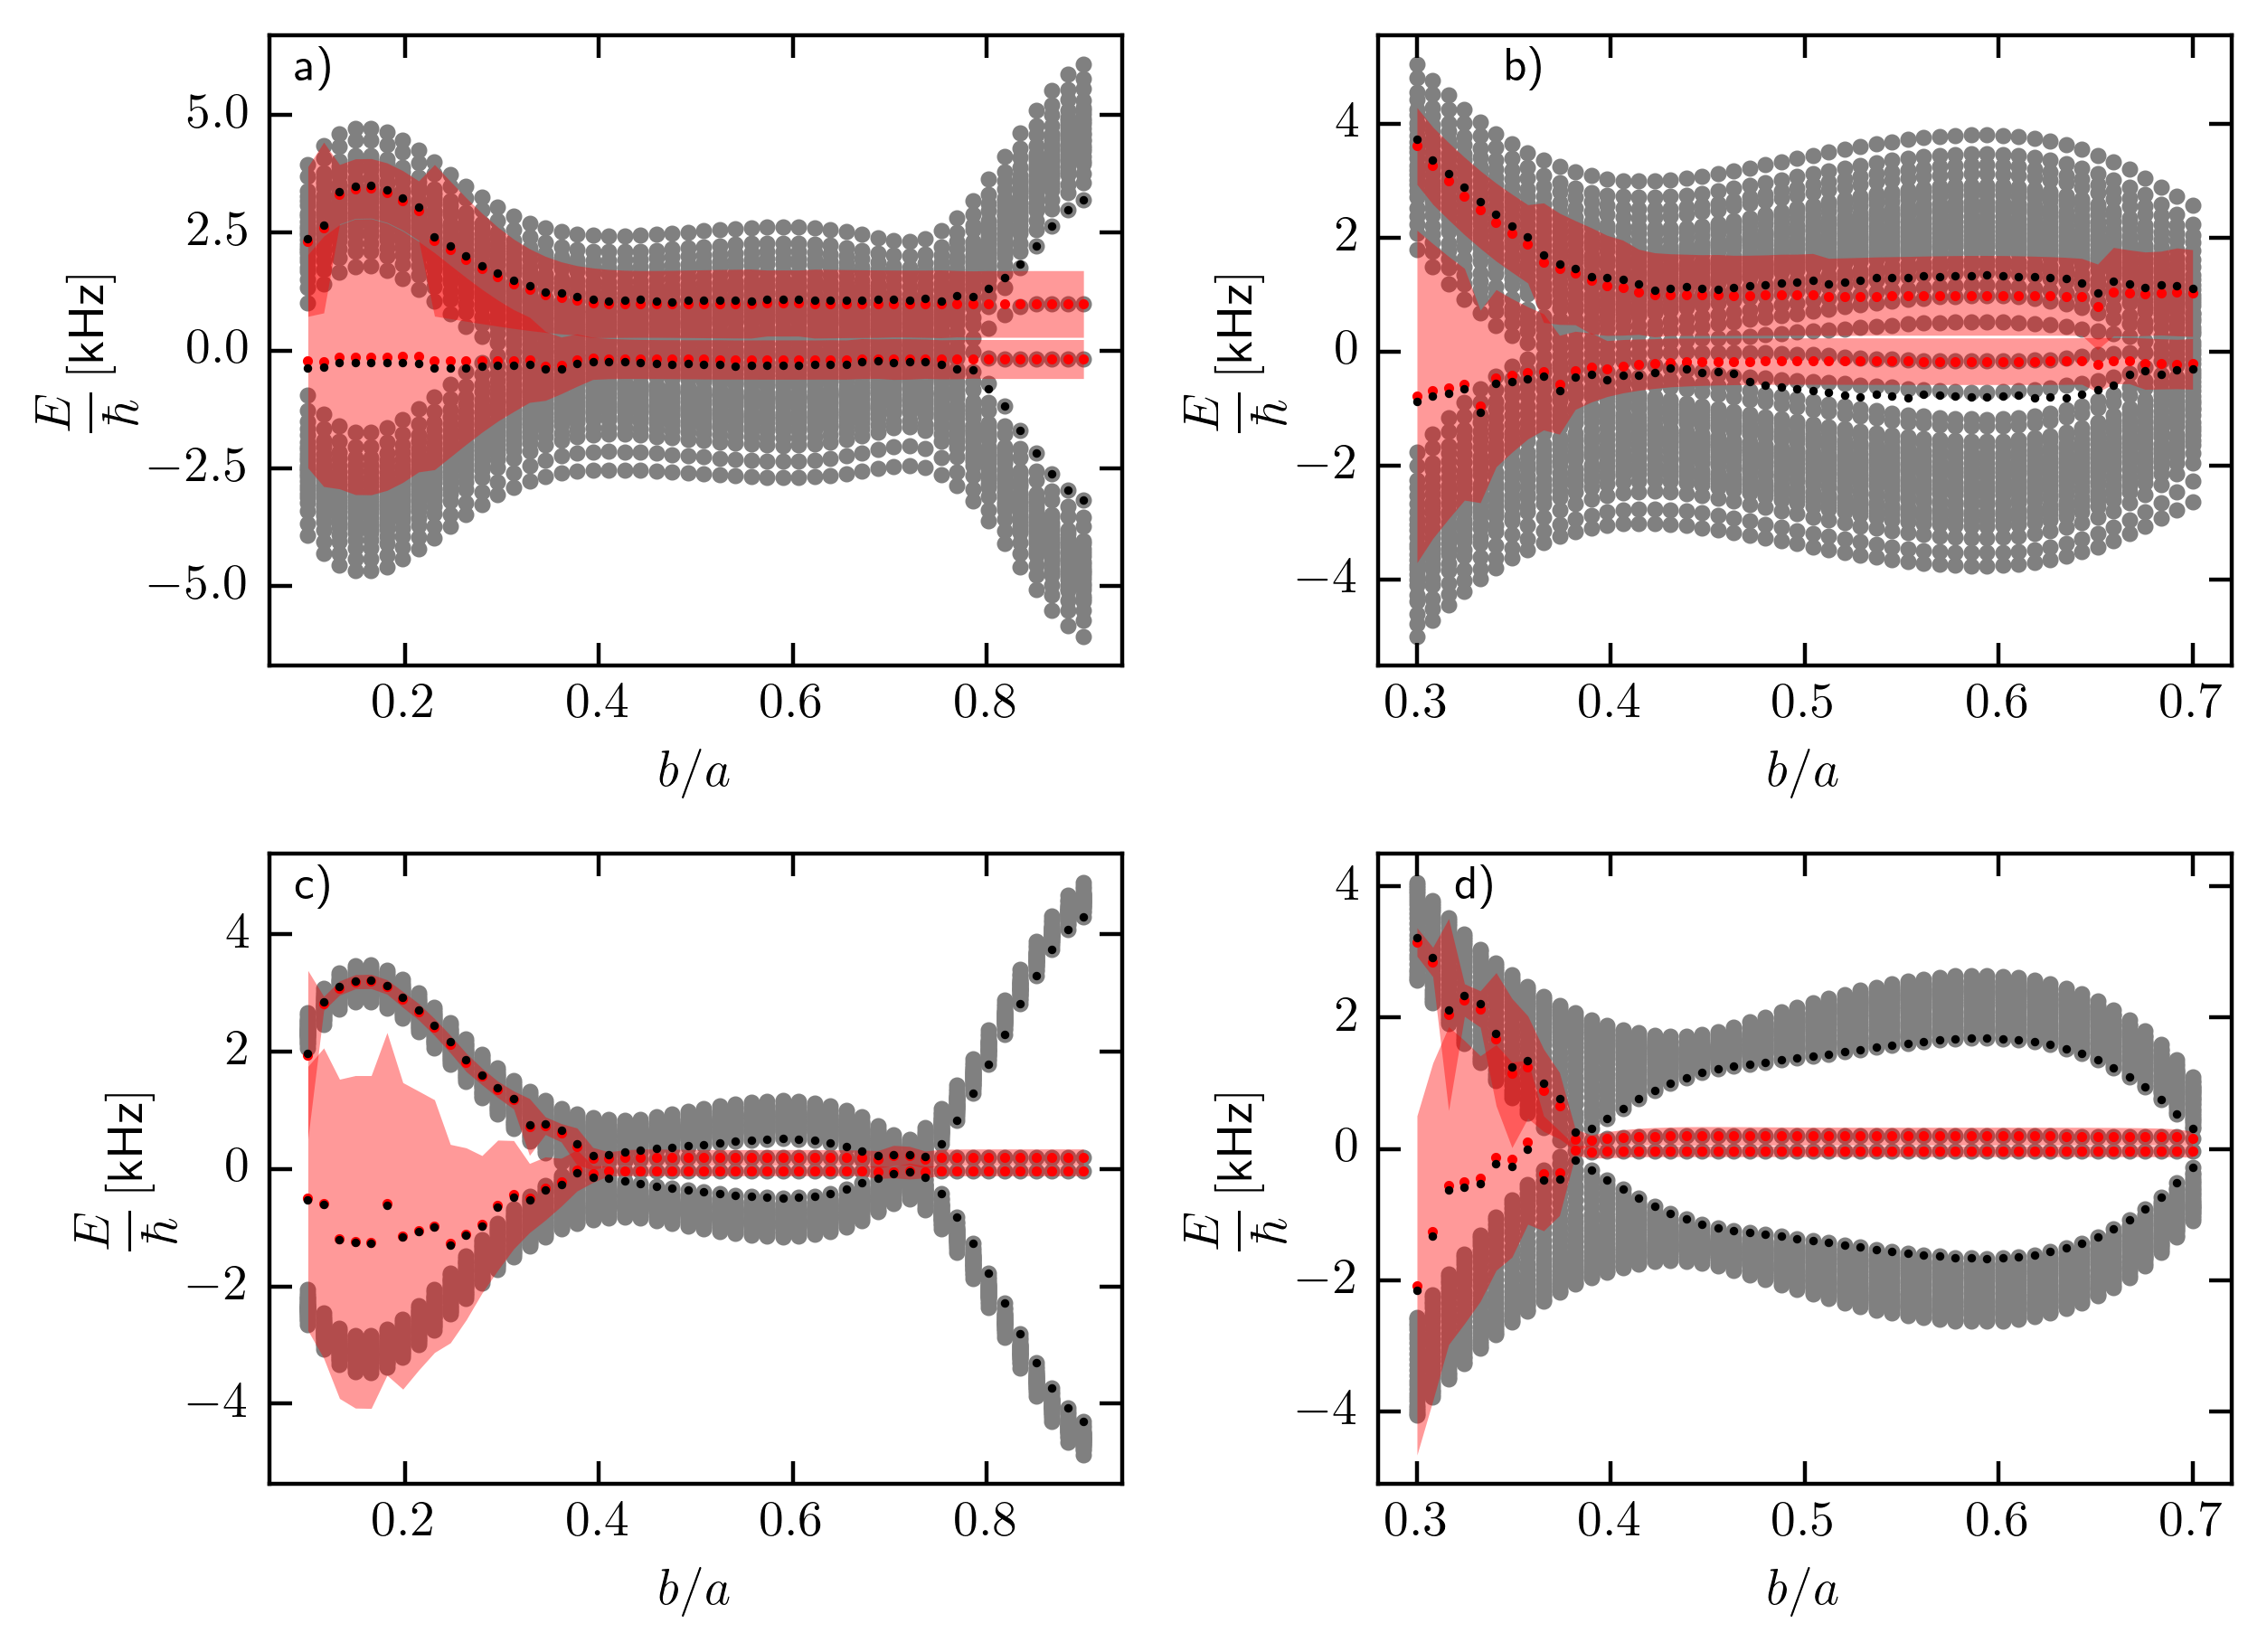

In [12]:
intercectcolor = "#CBC50A"
lwidth = 1.5
N = 50
# N_s = 1000
from random import random
setup = Setup_Fig(name_of_plot='lam2_anal_ml.png',fig_width=7,fig_height=5.2,xax_share=False,yax_share=False)
threshholds = [0.4,0.2]
fig, axes = setup.return_fig((2,2))
# bs = np.linspace(0.3,0.7,N)
formater = []
for q in range(2):
    deviation = [1,0.2][q]
    bss = [np.linspace(0.1,0.9,N),np.linspace(0.3,0.7,N)]
    ratios = [4.79861365/1000,12.66835467/1000]

    # fig, axes = plt.subplots(1,2)
    for l in range(2):
        bs = bss[l]
        ax = axes[q,l]
        if l == 0:
            ax.text(0.03,0.93,s=r"{})".format(['a','b','c','d'][2*q+l]),transform = ax.transAxes,fontsize=9)
        else:
            if q==1:
                ax.text(0.09,0.93,s=r"{})".format(['a','b','c','d'][2*q+l]),transform = ax.transAxes,fontsize=9)
            else:
                ax.text(0.15,0.93,s=r"{})".format(['a','b','c','d'][2*q+l]),transform = ax.transAxes,fontsize=9)
        treshhold = threshholds[q]#0.4
        means = np.mean(eigenvals[:,q*2+l,:,:-2],axis=0)
        means_gap = np.mean(eigenvals[:,q*2+l,:,-2:],axis=0)
        std = np.std(eigenvals[:,q*2+l,:,:-2],axis=0)
        std_gap = np.std(eigenvals[:,q*2+l,:,-2:],axis=0)
        gaps_mean = np.mean(gaps[:,:,q*2+l],axis=0)
        b_gap = []
        upper_bound = []
        lower_bound = []
        
        # if l ==0 and q==0:
        #     ax.vlines(0.9,np.min(means)*0.9,np.max(means)*0.9,color =intercectcolor,linestyle = 'dashed',linewidth=lwidth)
        # elif l ==0 and q==1:
        #     ax.vlines(0.6,np.min(means)*0.9,np.max(means)*0.9,color = intercectcolor,linestyle = 'dashed',linewidth=lwidth)
        for i in range(N):
            gap = False
            for j in range(2,chain_length-2):
                if (np.abs(means[i,j,0]-means[i,j+1,0])>treshhold and np.abs(means[i,j-1,0]-means[i,j-2,0])>treshhold):
                    upper_bound.append(means[i,j,0]+std[i,j,0])
                # elif (np.abs(means[i,j+1,0]-means[i,j+2,0])>treshhold and np.abs(means[i,j,0]-means[i,j-1,0])>treshhold):
                    # gap = True
                    lower_bound.append(means[i,j-1,0]-std[i,j-1,0])
                    b_gap.append(bs[i])
                else:
                    gap = False
            ax.scatter(np.ones(chain_length)*bs[i],np.real(means[i,:,0]),color="0.5",s=5)
            # means_gap = sort_eigenvalues(means[i,:,0],means[i,:,1:].T)
            # if gap:
            #     b_gap.append(bs[i])
            #     # upper_bound.append(np.max(means_gap[i,:2,0]+std[i,:2,0]))
            #     # lower_bound.append(np.min(means_gap[i,:2,0]-std[i,:2,0]))
            #     upper_bound.append(np.max(means_gap[i,:2,0]+0*treshhold))
            #     lower_bound.append(np.min(means_gap[i,:2,0]-0*treshhold))
                # ax.errorbar(np.ones(2)*bs[i],means_gap[i,:2,0],yerr=std[i,:2,0],markersize=20,color="red")
        for k in range(2):
            ax.scatter(bs,np.real(means_gap[:,k,0]),color='red',s=1)
            ax.fill_between(bs,np.real(means_gap[:,k,0])+np.abs(std_gap[:,k,0]),np.real(means_gap[:,k,0])-np.abs(std_gap[:,k,0]),color='red',alpha=0.4,linewidth=0)
        ax.scatter(bs,np.real(means_gap[:,1,0])+np.abs(gaps_mean[:,1,1]),color='0')#,linestyle='dotted')
        ax.scatter(bs,np.real(means_gap[:,0,0])-np.abs(gaps_mean[:,0,0]),color='0')#,linestyle='dashed')
        # ax.fill_between(b_gap,lower_bound,upper_bound,color='blue',alpha=0.4,linewidth=0)
        ax.set_xlabel(r"$$b/a$$")
        ax.set_ylabel(r"$$\frac{E}{\hbar}\,[\text{kHz}]$$",labelpad=2)
        formater.append( lambda x=q, y=l, axis=ax: setup.format_ax(axis,(2,2),j=l,bottom=q,set_ticks=False)   )
        ax = formater[2*q+l]()
# axes[1,0].set_xlabel(r"$$b/a$$"),rotation=0
# axes[1,1].set_xlabel(r"$$b/a$$")
plt.subplots_adjust(wspace=0.3,hspace=0.3)
# plt.savefig("/home//christian/Documents/master/protocol/pictures/"+"edge_stability_trapnoise_x_version2.pdf",bbox_inches='tight')

plt.show()


In [ ]:
single_points_1 = []

In [ ]:
N = 50
N_s = 20000
b0 = 0.9
ratio = 4.79861365/1000
# ratio = 12.66835467/1000
def wrap_loop(s,trash):
  
    np.random.seed(s)
    random_vec = np.random.normal(0,1,chain_length)
    
    dmat = hopping_Ham_adapted_random(random_vec,b0,h,ratio,1,chain_length,dip_derivative_full_vec,d)*ratio
    # if not np.all(np.abs(np.diag(dmat))==0):
    #     print("non_zero_diagonal: ",q,l,s,i)
    eig, vec = np.linalg.eig(dmat)
    eigen = sort_eigenvalues_energies(np.real(eig),vec)
    gapmod = sorted(sort_eigenvalues(np.real(eig),vec)[:2],key = lambda x: x[0])
    return np.vstack((eigen,gapmod),dtype=np.complex128)

                        
    
eigen_single = parallel_for([[0,N_s]],wrap_loop,chunk=100,core_number=20)
single_points_1.append(eigen_single)

In [ ]:
single_points = []

In [ ]:
N = 50
N_s = 20000
for i in range(3):
    b0 = [0.9,0.6,bss[0][22]]
    ratio = 4.79861365/1000
    # ratio = 12.66835467/1000
    def wrap_loop(s,trash):
    
        np.random.seed(s)
        random_vec = np.random.normal(0,0.2,chain_length)
        
        dmat = hopping_Ham_adapted_random(random_vec,b0,h,ratio,1,chain_length,dip_derivative_full_vec,d)*ratio
        # if not np.all(np.abs(np.diag(dmat))==0):
        #     print("non_zero_diagonal: ",q,l,s,i)
        eig, vec = np.linalg.eig(dmat)
        eigen = sort_eigenvalues_energies(np.real(eig),vec)
        gapmod = sorted(sort_eigenvalues(np.real(eig),vec)[:2],key = lambda x: x[0])
        return np.vstack((eigen,gapmod),dtype=np.complex128)

                            
        
    eigen_single = parallel_for([[0,N_s]],wrap_loop,chunk=100,core_number=20)
    single_points.append([b0,eigen_single])

In [ ]:
def return_gaps(eigen_single): 
    Ns = eigen_single.shape[0]
    index = np.zeros((Ns,2),dtype=np.int16)
    degeneracy = np.zeros_like(index)
    nexti = np.zeros((Ns,2,2),dtype=np.int16)
    gaps = np.zeros((Ns,2,2))
    edges = np.zeros((Ns,2,chain_length+1))
    energies = np.zeros((Ns,chain_length))
    for i in range(Ns):
        
                energies[i] = sorted(np.real(eigen_single[i,:-2,0]),key= lambda x: np.abs(x))
                for k in range(2):
                    indo = np.where(eigen_single[i,-2+k,0]==eigen_single[i,:-2,0])
                    # if len(indo)==1:
                    index[i,k] = indo[0][0]
                    degeneracy[i,] = len(indo[0])
                
                # edg = eigen_single[i,index[i,]]
                # index[i,] = sorted(index[i,],reverse=True)
                # edges[i,] = sort_eigenvalues_energies(edg[:,0].T,np.abs(edg[:,1:].T))
                    nexti[i,k,0] = indo[0][0]-1*(1+k)
                    nexti[i,k,1] = indo[0][0]+1*(2-k)
                
                gaps[i,:,0] = np.abs(eigen_single[i,index[i,],0]-eigen_single[i,nexti[i,:,0],0])
                gaps[i,:,1] = np.abs(eigen_single[i,index[i,],0]-eigen_single[i,nexti[i,:,1],0]) 
    return gaps


def return_occupation(eigen_single):
    edge_size = 1
    return (np.sum(np.abs(eigen_single[:,-2:,1:1+edge_size])**2,axis=2)+
                                                    np.sum(np.abs(eigen_single[:,-2:,-edge_size:])**2,axis=2))/np.sum(np.abs(eigen_single[:,-2:,1+edge_size:-edge_size])**2,axis=2)

In [ ]:
edge_size = 1
edge_occupation = (np.sum(np.abs(eigenvals[:,:,:,-2:,1:1+edge_size])**2,axis=4)+
                                                np.sum(np.abs(eigenvals[:,:,:,-2:,-edge_size:])**2,axis=4))/np.sum(np.abs(eigenvals[:,:,:,-2:,1+edge_size:-edge_size])**2,axis=4)
occupation_mean = np.mean(edge_occupation,axis=0)
occupation_std = np.std(edge_occupation,axis=0)
setup = Setup_Fig(name_of_plot='lam2_anal_ml.png',fig_width=7,fig_height=5,xax_share=False,yax_share=False)
fig, axes = setup.return_fig((2,2))
# bs = np.linspace(0.3,0.7,N)
ond = 0
formater = []
for q in range(2):
   
    # fig, axes = plt.subplots(1,2)
    # for l in range(2):
        l = 0
        bs = bss[l]
        ax = axes[0,q]
        # if l == 0:
        ax.text(0.06,0.89,s=r"{})".format(['a','b','b','d'][2*q+l]),transform = ax.transAxes,fontsize=9)
        ax.errorbar(bs,occupation_mean[2*q+l,:,ond],yerr=occupation_std[2*q+l,:,ond],color='0.5',marker=".",barsabove=True,linestyle='none',capthick=0.5,capsize=1,markersize=4,linewidth=0.7)
        ax.set_xlabel(r"$b/a$")
        ax.set_ylabel(r"$$\frac{n_\text{edge}}{n_\text{bulk}}$$",rotation=0,labelpad=18)
        ax.ticklabel_format(style='sci', axis='y', scilimits=(4, 5), useMathText=True)


plt.subplots_adjust(wspace=0.3,hspace=0.3)
start = 25
stop = 36
# axins = ax.inset_axes(
#     [0.5, 0.5, 0.47, 0.47],
#     xlim=(bs[start], bs[stop]), ylim=(0, 500), xticklabels=[], yticklabels=[])
xex = 0.34
yex = 0.25
x0, y0 = 0.4, 0.25
wspace = 0.2
axins = ax.inset_axes(
    [x0, y0, xex, yex],transform=ax.transAxes)
axins2 = ax.inset_axes(
    [x0, y0+yex+wspace, xex, yex],transform=ax.transAxes)
axins.errorbar(bs[start:stop],occupation_mean[2*q+l,start:stop,ond],yerr=occupation_std[2*q+l,start:stop,ond],color='0.5',marker=".",barsabove=True,linestyle='none',capthick=0.5,capsize=1,markersize=4,linewidth=0.7)
lsize = 8
axins.tick_params(axis="both",labelsize=lsize,direction="in")
axins2.tick_params(axis="both",labelsize=lsize,direction="in")

gapi = return_gaps(single_points[1][1])
axins2.hist(-gapi[:,0,0],30,color="#E7390DDB")
axins2.hist(gapi[:,1,1],30,color="#A81409D2")
axins2.set_ylabel(r"counts",fontsize=8)
axins2.set_xlabel(r"energy gap [kHz]",fontsize=8,labelpad=0.5)
# ax.indicate_inset_zoom(axins, edgecolor="black")
exon = ax.indicate_inset([bs[start],-200,bs[stop]-bs[start],500],inset_ax=axins,edgecolor=intercectcolor,facecolor='none',alpha=1)
ax = axes[0,0]
axins3 = ax.inset_axes(
    [0.52, 0.7, xex, yex],transform=ax.transAxes)
gapo = return_gaps(single_points_1[0][1])
axins3.hist(-gapo[:,0,0],30,color="#E7390DDB")
axins3.hist(gapo[:,1,1],30,color="#A81409D2")
axins3.set_ylabel(r"counts",fontsize=8)
axins3.set_xlabel(r"energy gap [kHz]",fontsize=8,labelpad=0.5)
axins3.tick_params(axis="both",labelsize=lsize,direction="in")
inx, iny = 0.06, 800
exon3 = ax.indicate_inset([bs[-1]-inx/2,occupation_mean[0,-1,ond]-iny/2,inx,iny],inset_ax=axins3,edgecolor=intercectcolor,facecolor='none',alpha=1)
axes[0,0]= setup.format_ax(axes[0,0],shape=(1,2),set_ticks=False)
axes[0,1]= setup.format_ax(axes[0,1],shape=(1,2),set_ticks=False)
occi1 = return_occupation(single_points_1[0][1])
occi03 = return_occupation(single_points[0][1])
axes[1,0].hist(occi1[:,ond],30,color="#A81409D2")
axes[1,1].hist(occi03[:,ond],30,color="#A81409D2") 
axes[1,0].set_ylabel(r"share of 20\,000 samples")
axes[1,0].set_xlabel(r"$$\frac{n_\text{edge}}{n_\text{bulk}}$$")
axes[1,1].set_ylabel(r"share of 20\,000 samples")
axes[1,1].set_xlabel(r"$$\frac{n_\text{edge}}{n_\text{bulk}}$$")
axes[1,0]= setup.format_ax(axes[1,0],shape=(1,2),set_ticks=False)
axes[1,1]= setup.format_ax(axes[1,1],shape=(1,2),set_ticks=False)
axes[1,0].text(0.06,0.89,s=r"c)",transform = axes[1,0].transAxes,fontsize=9)
axes[1,1].text(0.06,0.89,s=r"d)",transform = axes[1,1].transAxes,fontsize=9)
axes[1,0].text(0.19,0.75,s=r"\begin{align*}&b/a=0.9\\&\delta\omega=1\%\end{align*}",transform = axes[1,0].transAxes,fontsize=9)
axes[1,1].text(0.19,0.75,s=r"\begin{align*}&b/a=0.9\\&\delta\omega=0.2\%\end{align*}",transform = axes[1,1].transAxes,fontsize=9)
# plt.savefig("/home//christian/Documents/master/protocol/pictures/"+"edge_gap_stability_trapnoise_x.pdf",bbox_inches='tight')


plt.show()